In [ ]:
# Cell 1: Environment setup
import io
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11

### **Step 1.5: Set Google Sheet Credentials Securely**

Choose **one** of the methods below to set your credentials before running the data fetching script. Since we want to upload this notebook to GitHub, we keep these inputs dynamic or hidden.

In [ ]:
#@title Method A: Interactive Form Fields (Leave empty on GitHub!)
SHEET_ID = "" #@param {type:"string"}
GID = "" #@param {type:"string"}

if SHEET_ID and GID:
    print("✅ Credentials configured successfully via form fields!")

✅ Credentials configured successfully via form fields!


In [ ]:
# Cell 2: Fetch and clean data with Google Authentication
import pandas as pd
import numpy as np
import io
from google.colab import auth
import gspread
from google.auth import default

# 1. Authenticate to access your private Google Sheet
try:
    auth.authenticate_user()
    creds, _ = default()
    gc = gspread.authorize(creds)

    # 2. Open the sheet using your secure SHEET_ID
    sh = gc.open_by_key(SHEET_ID)

    # 3. Get the specific tab using your GID or index (0 is the first worksheet)
    # If you prefer using GID specifically, we can fetch all worksheets and match GID
    worksheet = None
    for ws in sh.worksheets():
        if str(ws.id) == str(GID):
            worksheet = ws
            break
    if worksheet is None:
        worksheet = sh.get_worksheet(0) # Fallback to first sheet if GID matches nothing

    # Convert to DataFrame
    records = worksheet.get_all_records()
    df_raw = pd.DataFrame(records)
    print("✅ Successfully connected and authenticated with Google Sheets!")
except Exception as e:
    print(f"❌ Authentication or Access Error: {e}")
    print("Make sure SHEET_ID and GID are correct, and your logged-in Google Account has access to the sheet.")

# Clean column headers
df_raw.columns = [c.strip() for c in df_raw.columns]

# Filter valid assay records and drop empty rows using corrected column names
df = df_raw.dropna(subset=["Code", "Final Syndecan (ng/mL)-linear"]).copy()

# Extract HN and Visit from the 'Code' column (e.g., 'SDC001_0h' -> HN: 'SDC001', Visit: 0)
df["HN"] = df["Code"].apply(lambda x: str(x).split("_")[0].strip())

def parse_visit_from_code(code_val):
    val_str = str(code_val).lower()
    if "72h" in val_str:
        return 72
    return 0

df["Visit"] = df["Code"].apply(parse_visit_from_code)
df["Visit_Label"] = df["Visit"].map({0: "Baseline (0h)", 72: "72 Hours"})
df["Syndecan_1"] = pd.to_numeric(df["Final Syndecan (ng/mL)-linear"], errors="coerce")

# Load pre-calculated log values directly from the sheet as requested
df["Log_Syndecan_1"] = pd.to_numeric(df["Final Syndecan (ng/mL)-log"], errors="coerce")

# Convert H:M processing delay into numeric hours
def parse_hm_to_hours(val):
  if pd.isna(val):
    return np.nan
  parts = str(val).strip().split(":")
  if len(parts) == 2:
    try:
      return float(parts[0]) + float(parts[1]) / 60.0
    except ValueError:
      return np.nan
  return np.nan

if "H:M" in df.columns:
    df["Processing_Delay_Hours"] = df["H:M"].apply(parse_hm_to_hours)
else:
    df["Processing_Delay_Hours"] = np.nan

# Standardize Hemolysis category if present, otherwise default to "None"
if "Plasma Hemolysis" in df.columns:
    df["Plasma_Hemolysis" ] = df["Plasma Hemolysis"].fillna("None").astype(str).str.strip()
else:
    df["Plasma_Hemolysis"] = "None"

# Rename and assign exactly requested columns
df["Plasma Hemolysis"] = df["Plasma_Hemolysis"]
df["Final Syndecan (ng/mL)-log"] = df["Log_Syndecan_1"]

# Final requested headers list
requested_headers = [
    "Code",
    "Visit",
    "H:M",
    "Plasma Hemolysis",
    "Final Syndecan (ng/mL)-linear",
    "Final Syndecan (ng/mL)-log"
]

print(f"Loaded {len(df)} valid assay records across {df['HN'].nunique()} unique patients.")
display(df[requested_headers].head())

✅ Successfully connected and authenticated with Google Sheets!
Loaded 56 valid assay records across 29 unique patients.


,Code,Visit,H:M,Plasma Hemolysis,Final Syndecan (ng/mL)-linear,Final Syndecan (ng/mL)-log
0,SDC001_0h,0,43:40,1,35.645,46.049
1,SDC002_0h,0,19:40,None,268.763,241.828
2,SDC003_0h,0,15:20,partial,282.59,250.963
3,SDC004_0h,0,14:50,None,32.515,41.876
4,SDC001_72h,72,0:30,None,42.435,54.617


In [ ]:
# Convert 'Final Syndecan (ng/mL)-linear' to numeric to ensure it is included in numerical statistics
df['Final Syndecan (ng/mL)-linear'] = pd.to_numeric(df['Final Syndecan (ng/mL)-linear'], errors='coerce')

# Recalculate summary statistics for both columns
summary_stats = df[["Final Syndecan (ng/mL)-linear", "Final Syndecan (ng/mL)-log"]].describe()
display(summary_stats)

,Final Syndecan (ng/mL)-linear,Final Syndecan (ng/mL)-log
count,40.000000,40.000000
mean,160.224225,154.887175
std,102.135740,83.513565
min,32.515000,41.876000
25%,50.236000,63.818250
50%,162.585500,165.952000
75%,266.756750,240.491000
max,300.306000,262.473000


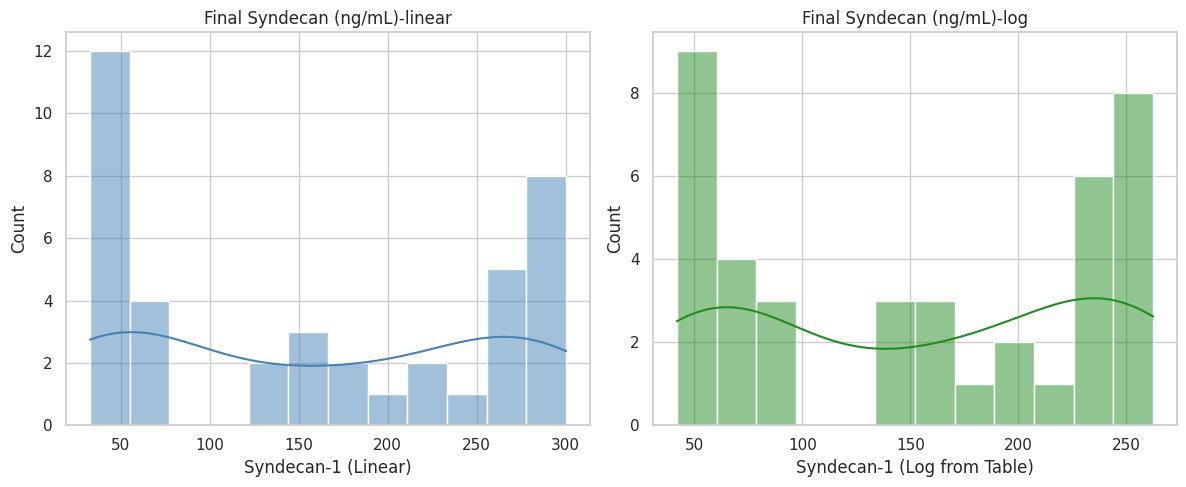

Final Syndecan (ng/mL)-linear Shapiro-Wilk p-value: 7.6233e-05
Final Syndecan (ng/mL)-log Shapiro-Wilk p-value: 8.7118e-05


In [ ]:
# Cell 3: Assess distribution of Syndecan-1 (Linear vs. Log from Table)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Linear distribution
sns.histplot(
    df["Final Syndecan (ng/mL)-linear"], kde=True, ax=axes[0], color="steelblue", bins=12
)
axes[0].set_title("Final Syndecan (ng/mL)-linear")
axes[0].set_xlabel("Syndecan-1 (Linear)")

# Log distribution
sns.histplot(
    df["Final Syndecan (ng/mL)-log"], kde=True, ax=axes[1], color="forestgreen", bins=12
)
axes[1].set_title("Final Syndecan (ng/mL)-log")
axes[1].set_xlabel("Syndecan-1 (Log from Table)")

plt.tight_layout()
plt.show()

# Shapiro-Wilk test for normality
sw_linear = stats.shapiro(df["Final Syndecan (ng/mL)-linear"].dropna())
sw_log = stats.shapiro(df["Final Syndecan (ng/mL)-log"].dropna())

print(f"Final Syndecan (ng/mL)-linear Shapiro-Wilk p-value: {sw_linear.pvalue:.4e}")
print(f"Final Syndecan (ng/mL)-log Shapiro-Wilk p-value: {sw_log.pvalue:.4e}")

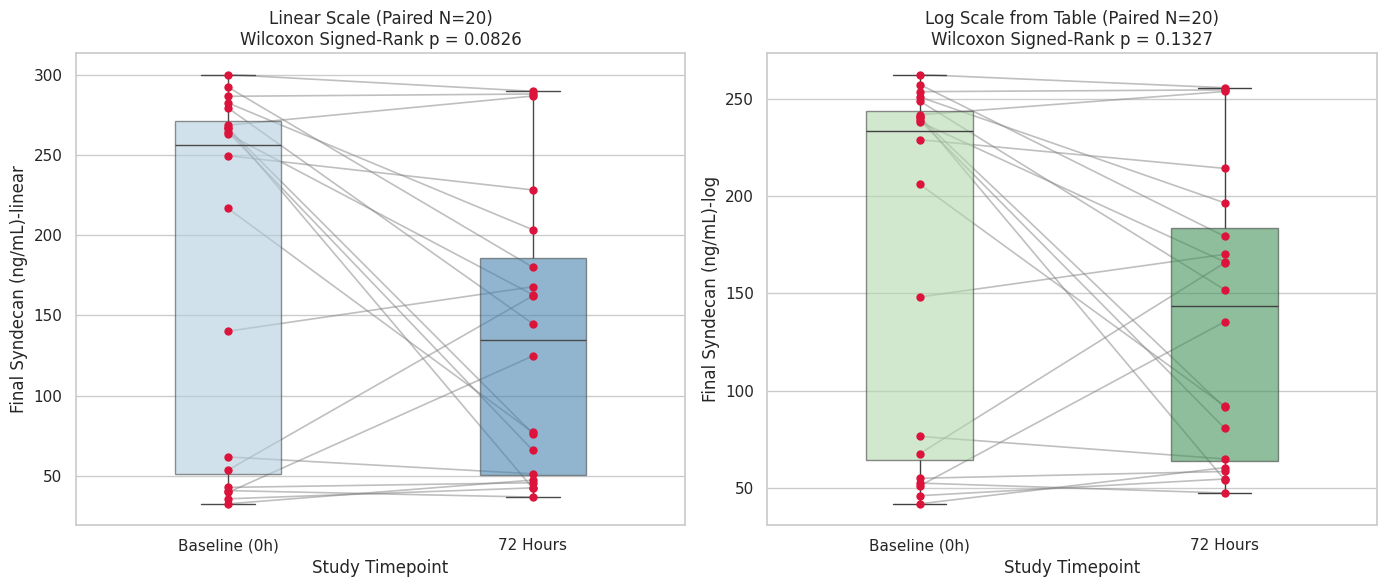

In [ ]:
# Cell 4: Paired analysis across timepoints (Linear vs. Log from Table)
# Reshape to wide format for paired testing
df_paired_linear = df.pivot(index="HN", columns="Visit", values="Final Syndecan (ng/mL)-linear").dropna()
df_paired_linear.columns = ["T0", "T72"]

df_paired_log = df.pivot(index="HN", columns="Visit", values="Final Syndecan (ng/mL)-log").dropna()
df_paired_log.columns = ["T0", "T72"]

# Wilcoxon signed-rank test
stat_linear, p_val_linear = stats.wilcoxon(df_paired_linear["T0"], df_paired_linear["T72"])
stat_log, p_val_log = stats.wilcoxon(df_paired_log["T0"], df_paired_log["T72"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Linear Scale
for idx, row in df_paired_linear.iterrows():
    axes[0].plot(
        ["Baseline (0h)", "72 Hours"],
        [row["T0"], row["T72"]],
        color="gray",
        alpha=0.5,
        linewidth=1.2,
    )
sns.boxplot(
    data=df,
    x="Visit_Label",
    y="Final Syndecan (ng/mL)-linear",
    hue="Visit_Label",
    ax=axes[0],
    palette="Blues",
    width=0.35,
    boxprops=dict(alpha=0.6),
    legend=False
)
sns.stripplot(
    data=df,
    x="Visit_Label",
    y="Final Syndecan (ng/mL)-linear",
    ax=axes[0],
    color="crimson",
    size=6,
    jitter=False,
)
axes[0].set_title(f"Linear Scale (Paired N={len(df_paired_linear)})\nWilcoxon Signed-Rank p = {p_val_linear:.4f}")
axes[0].set_ylabel("Final Syndecan (ng/mL)-linear")
axes[0].set_xlabel("Study Timepoint")

# Plot 2: Log Scale from Table
for idx, row in df_paired_log.iterrows():
    axes[1].plot(
        ["Baseline (0h)", "72 Hours"],
        [row["T0"], row["T72"]],
        color="gray",
        alpha=0.5,
        linewidth=1.2,
    )
sns.boxplot(
    data=df,
    x="Visit_Label",
    y="Final Syndecan (ng/mL)-log",
    hue="Visit_Label",
    ax=axes[1],
    palette="Greens",
    width=0.35,
    boxprops=dict(alpha=0.6),
    legend=False
)
sns.stripplot(
    data=df,
    x="Visit_Label",
    y="Final Syndecan (ng/mL)-log",
    ax=axes[1],
    color="crimson",
    size=6,
    jitter=False,
)
axes[1].set_title(f"Log Scale from Table (Paired N={len(df_paired_log)})\nWilcoxon Signed-Rank p = {p_val_log:.4f}")
axes[1].set_ylabel("Final Syndecan (ng/mL)-log")
axes[1].set_xlabel("Study Timepoint")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the delta columns first to prevent KeyError
df_paired_linear['Delta_Linear'] = df_paired_linear['T72'] - df_paired_linear['T0']
df_paired_log['Delta_Log'] = df_paired_log['T72'] - df_paired_log['T0']

# 1. Trajectory Groups for Non-Log (Linear) Data
def classify_linear(delta):
    if delta < -10:
        return "Decreased (>10 ng/mL)"
    elif delta > 10:
        return "Increased (>10 ng/mL)"
    else:
        return "Stable (+/- 10 ng/mL)"

df_paired_linear['Group_Linear'] = df_paired_linear['Delta_Linear'].apply(classify_linear)
linear_counts = df_paired_linear['Group_Linear'].value_counts()
linear_pcts = df_paired_linear['Group_Linear'].value_counts(normalize=True) * 100

print("=== NON-LOG (LINEAR) TRAJECTORY GROUPS ===")
for grp in ["Decreased (>10 ng/mL)", "Stable (+/- 10 ng/mL)", "Increased (>10 ng/mL)"]:
    print(f"{grp}: {linear_counts.get(grp, 0)} patients ({linear_pcts.get(grp, 0.0):.1f}%)")

# 2. Trajectory Groups for Log Data
def classify_log(delta):
    if delta < -10:
        return "Decreased (>10 log units)"
    elif delta > 10:
        return "Increased (>10 log units)"
    else:
        return "Stable (+/- 10 log units)"

df_paired_log['Group_Log'] = df_paired_log['Delta_Log'].apply(classify_log)
log_counts = df_paired_log['Group_Log'].value_counts()
log_pcts = df_paired_log['Group_Log'].value_counts(normalize=True) * 100

print("\n=== LOG-TRANSFORMED TRAJECTORY GROUPS ===")
for grp in ["Decreased (>10 log units)", "Stable (+/- 10 log units)", "Increased (>10 log units)"]:
    print(f"{grp}: {log_counts.get(grp, 0)} patients ({log_pcts.get(grp, 0.0):.1f}%)")

=== NON-LOG (LINEAR) TRAJECTORY GROUPS ===
Decreased (>10 ng/mL): 11 patients (55.0%)
Stable (+/- 10 ng/mL): 4 patients (20.0%)
Increased (>10 ng/mL): 5 patients (25.0%)

=== LOG-TRANSFORMED TRAJECTORY GROUPS ===
Decreased (>10 log units): 10 patients (50.0%)
Stable (+/- 10 log units): 5 patients (25.0%)
Increased (>10 log units): 5 patients (25.0%)


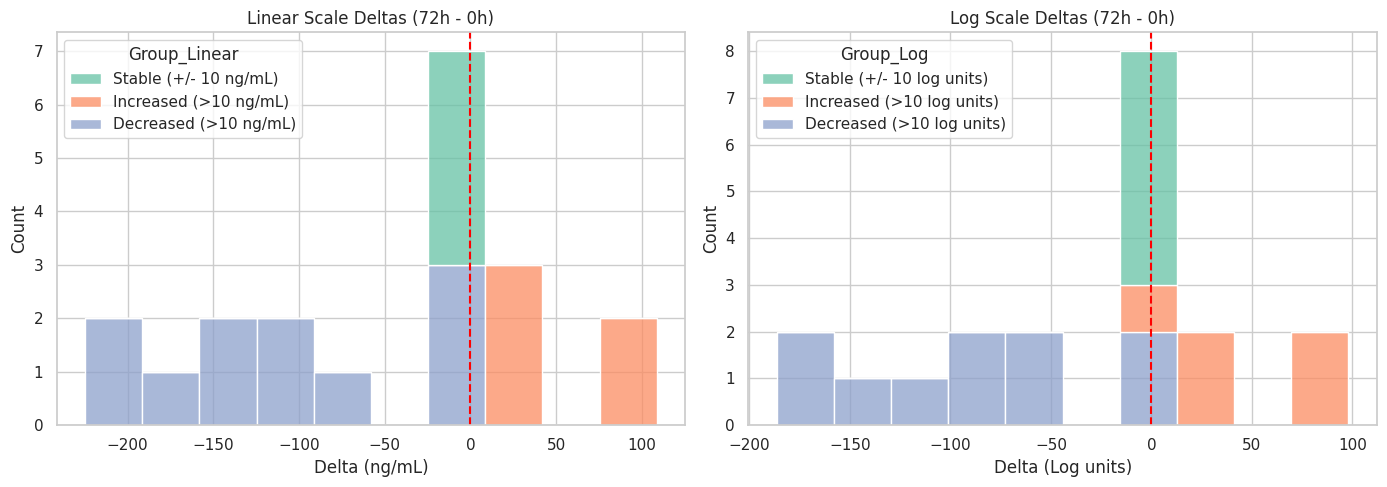

In [ ]:
# Compare side-by-side distribution of deltas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_paired_linear, x='Delta_Linear', hue='Group_Linear', bins=10, ax=axes[0], palette='Set2', multiple='stack')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title("Linear Scale Deltas (72h - 0h)")
axes[0].set_xlabel("Delta (ng/mL)")

sns.histplot(data=df_paired_log, x='Delta_Log', hue='Group_Log', bins=10, ax=axes[1], palette='Set2', multiple='stack')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title("Log Scale Deltas (72h - 0h)")
axes[1].set_xlabel("Delta (Log units)")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# กำหนดค่าเกณฑ์สำหรับข้อมูล Linear (หน่วย ng/mL)
# เราจะใช้ค่า median ของค่าตั้งต้น (T0) ในการแบ่งกลุ่มค่าตั้งต้นสูง/ต่ำ
median_t0_linear = df_paired_linear['T0'].median()
print(f"ค่ากลาง (Median) ของตั้งต้น (T0) สำหรับ Linear: {median_t0_linear:.3f} ng/mL\n")

def classify_four_groups_linear(row):
    t0 = row['T0']
    delta = row['Delta_Linear']

    # กลุ่มที่ 1: ติดตาม 72 h แล้วค่าสูงขึ้น (Delta > 10)
    if delta > 10:
        return "กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น)"
    # กลุ่มที่ 2: ติดตาม 72 h แล้วค่าต่ำลง (Delta < -10)
    elif delta < -10:
        return "กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)"
    # กลุ่มที่ 3 และ 4: ค่าค่อนข้างคงที่ (Stable: delta อยู่ระหว่าง -10 ถึง 10)
    else:
        if t0 < median_t0_linear:
            return "กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)"
        else:
            return "กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)"

df_paired_linear['Pattern_Group'] = df_paired_linear.apply(classify_four_groups_linear, axis=1)
linear_patterns = df_paired_linear['Pattern_Group'].value_counts()

print("=== การกระจายตัวในข้อมูลแบบ NON-LOG (LINEAR) ===")
for i in range(1, 5):
    group_name = [g for g in df_paired_linear['Pattern_Group'].unique() if f"กลุ่มที่ {i}" in g]
    if group_name:
        name = group_name[0]
        print(f"{name}: {linear_patterns.get(name, 0)} ราย")
    else:
        print(f"กลุ่มที่ {i}: 0 ราย")

# -----------------------------------------------------------------
# ทำแบบเดียวกันสำหรับข้อมูล Log
median_t0_log = df_paired_log['T0'].median()
print(f"\nค่ากลาง (Median) ของตั้งต้น (T0) สำหรับ Log: {median_t0_log:.3f}\n")

def classify_four_groups_log(row):
    t0 = row['T0']
    delta = row['Delta_Log']

    # กลุ่มที่ 1: ติดตาม 72 h แล้วค่าสูงขึ้น (Delta > 10)
    if delta > 10:
        return "กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น)"
    # กลุ่มที่ 2: ติดตาม 72 h แล้วค่าต่ำลง (Delta < -10)
    elif delta < -10:
        return "กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)"
    # กลุ่มที่ 3 และ 4: ค่าค่อนข้างคงที่ (Stable)
    else:
        if t0 < median_t0_log:
            return "กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)"
        else:
            return "กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)"

df_paired_log['Pattern_Group'] = df_paired_log.apply(classify_four_groups_log, axis=1)
log_patterns = df_paired_log['Pattern_Group'].value_counts()

print("=== การกระจายตัวในข้อมูลแบบ LOG-TRANSFORMED ===")
for i in range(1, 5):
    group_name = [g for g in df_paired_log['Pattern_Group'].unique() if f"กลุ่มที่ {i}" in g]
    if group_name:
        name = group_name[0]
        print(f"{name}: {log_patterns.get(name, 0)} ราย")
    else:
        print(f"กลุ่มที่ {i}: 0 ราย")

ค่ากลาง (Median) ของตั้งต้น (T0) สำหรับ Linear: 256.471 ng/mL

=== การกระจายตัวในข้อมูลแบบ NON-LOG (LINEAR) ===
กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น): 5 ราย
กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง): 11 ราย
กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เปลี่ยนแปลง): 3 ราย
กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เปลี่ยนแปลง): 1 ราย

ค่ากลาง (Median) ของตั้งต้น (T0) สำหรับ Log: 233.570

=== การกระจายตัวในข้อมูลแบบ LOG-TRANSFORMED ===
กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น): 5 ราย
กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง): 10 ราย
กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เปลี่ยนแปลง): 3 ราย
กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เปลี่ยนแปลง): 2 ราย


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# 1. Prepare Export Dataframe combining both Linear and Log Pattern Classifications with HN
df_export_patterns = pd.DataFrame({
    'HN': df_paired_linear.index,
    'Baseline_Linear': df_paired_linear['T0'],
    'T72_Linear': df_paired_linear['T72'],
    'Delta_Linear': df_paired_linear['Delta_Linear'],
    'Pattern_Linear': df_paired_linear['Pattern_Group'],
    'Baseline_Log': df_paired_log['T0'],
    'T72_Log': df_paired_log['T72'],
    'Delta_Log': df_paired_log['Delta_Log'],
    'Pattern_Log': df_paired_log['Pattern_Group']
}).reset_index(drop=True)

# Display the table
print("=== Patient Trajectory Patterns (Linear vs Log) ===")
display(df_export_patterns)

# Export to CSV
export_filename = "patient_trajectory_patterns.csv"
df_export_patterns.to_csv(export_filename, index=False)
files.download(export_filename)
print(f"Saved and downloaded: {export_filename}")

=== Patient Trajectory Patterns (Linear vs Log) ===


,HN,Baseline_Linear,T72_Linear,Delta_Linear,Pattern_Linear,Baseline_Log,T72_Log,Delta_Log,Pattern_Log
0,SDC001,35.645,42.435,6.790,กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เ...,46.049,54.617,8.568,กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เ...
1,SDC002,268.763,286.923,18.160,กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น),241.828,253.798,11.970,กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น)
2,SDC003,282.590,203.470,-79.120,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),250.963,196.569,-54.394,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)
3,SDC004,32.515,47.314,14.799,กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น),41.876,60.447,18.571,กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น)
4,SDC005,249.694,228.338,-21.356,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),228.994,214.262,-14.732,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)
5,SDC006,263.247,162.908,-100.339,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),238.145,166.202,-71.943,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)
6,SDC007,266.691,76.239,-190.452,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),240.447,91.368,-149.079,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)
7,SDC008,42.737,45.655,2.918,กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เ...,54.986,58.492,3.506,กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เ...
8,SDC009,300.306,289.903,-10.403,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),262.473,255.740,-6.733,กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เ...
9,SDC010,292.419,180.069,-112.350,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง),257.375,179.305,-78.070,กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved and downloaded: patient_trajectory_patterns.csv


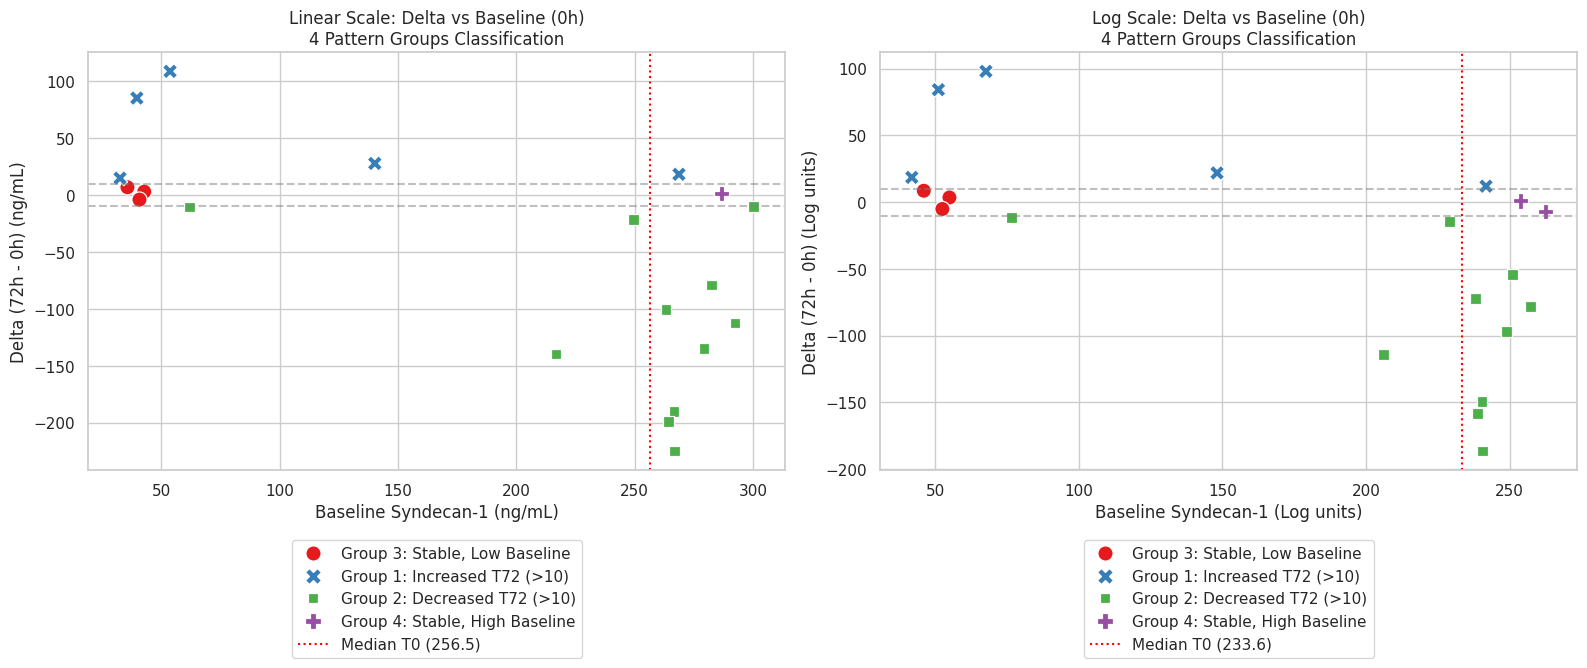

In [ ]:
# 2. Visualization of Classifications with English Labels for Font Compatibility
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Map Thai categories to clean English terms for display
map_eng = {
    "กลุ่มที่ 1 (ติดตาม 72 h แล้วค่าสูงขึ้น)": "Group 1: Increased T72 (>10)",
    "กลุ่มที่ 2 (ติดตาม 72 h แล้วค่าต่ำลง)": "Group 2: Decreased T72 (>10)",
    "กลุ่มที่ 3 (ค่าตั้งต้นต่ำ ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)": "Group 3: Stable, Low Baseline",
    "กลุ่มที่ 4 (ค่าตั้งต้นสูง ติดตาม 72 h แล้วไม่เปลี่ยนแปลง)": "Group 4: Stable, High Baseline"
}

df_plot = df_export_patterns.copy()
df_plot['Pattern_Linear_Eng'] = df_plot['Pattern_Linear'].map(map_eng)
df_plot['Pattern_Log_Eng'] = df_plot['Pattern_Log'].map(map_eng)

# Plot 1: Linear Scale
sns.scatterplot(
    data=df_plot,
    x='Baseline_Linear',
    y='Delta_Linear',
    hue='Pattern_Linear_Eng',
    style='Pattern_Linear_Eng',
    palette='Set1',
    s=120,
    ax=axes[0]
)
axes[0].axhline(10, color='gray', linestyle='--', alpha=0.5)
axes[0].axhline(-10, color='gray', linestyle='--', alpha=0.5)
axes[0].axvline(median_t0_linear, color='red', linestyle=':', label=f'Median T0 ({median_t0_linear:.1f})')
axes[0].set_title("Linear Scale: Delta vs Baseline (0h)\n4 Pattern Groups Classification")
axes[0].set_xlabel("Baseline Syndecan-1 (ng/mL)")
axes[0].set_ylabel("Delta (72h - 0h) (ng/mL)")
axes[0].legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=1)

# Plot 2: Log Scale
sns.scatterplot(
    data=df_plot,
    x='Baseline_Log',
    y='Delta_Log',
    hue='Pattern_Log_Eng',
    style='Pattern_Log_Eng',
    palette='Set1',
    s=120,
    ax=axes[1]
)
axes[1].axhline(10, color='gray', linestyle='--', alpha=0.5)
axes[1].axhline(-10, color='gray', linestyle='--', alpha=0.5)
axes[1].axvline(median_t0_log, color='red', linestyle=':', label=f'Median T0 ({median_t0_log:.1f})')
axes[1].set_title("Log Scale: Delta vs Baseline (0h)\n4 Pattern Groups Classification")
axes[1].set_xlabel("Baseline Syndecan-1 (Log units)")
axes[1].set_ylabel("Delta (72h - 0h) (Log units)")
axes[1].legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=1)

plt.tight_layout()
plt.show()

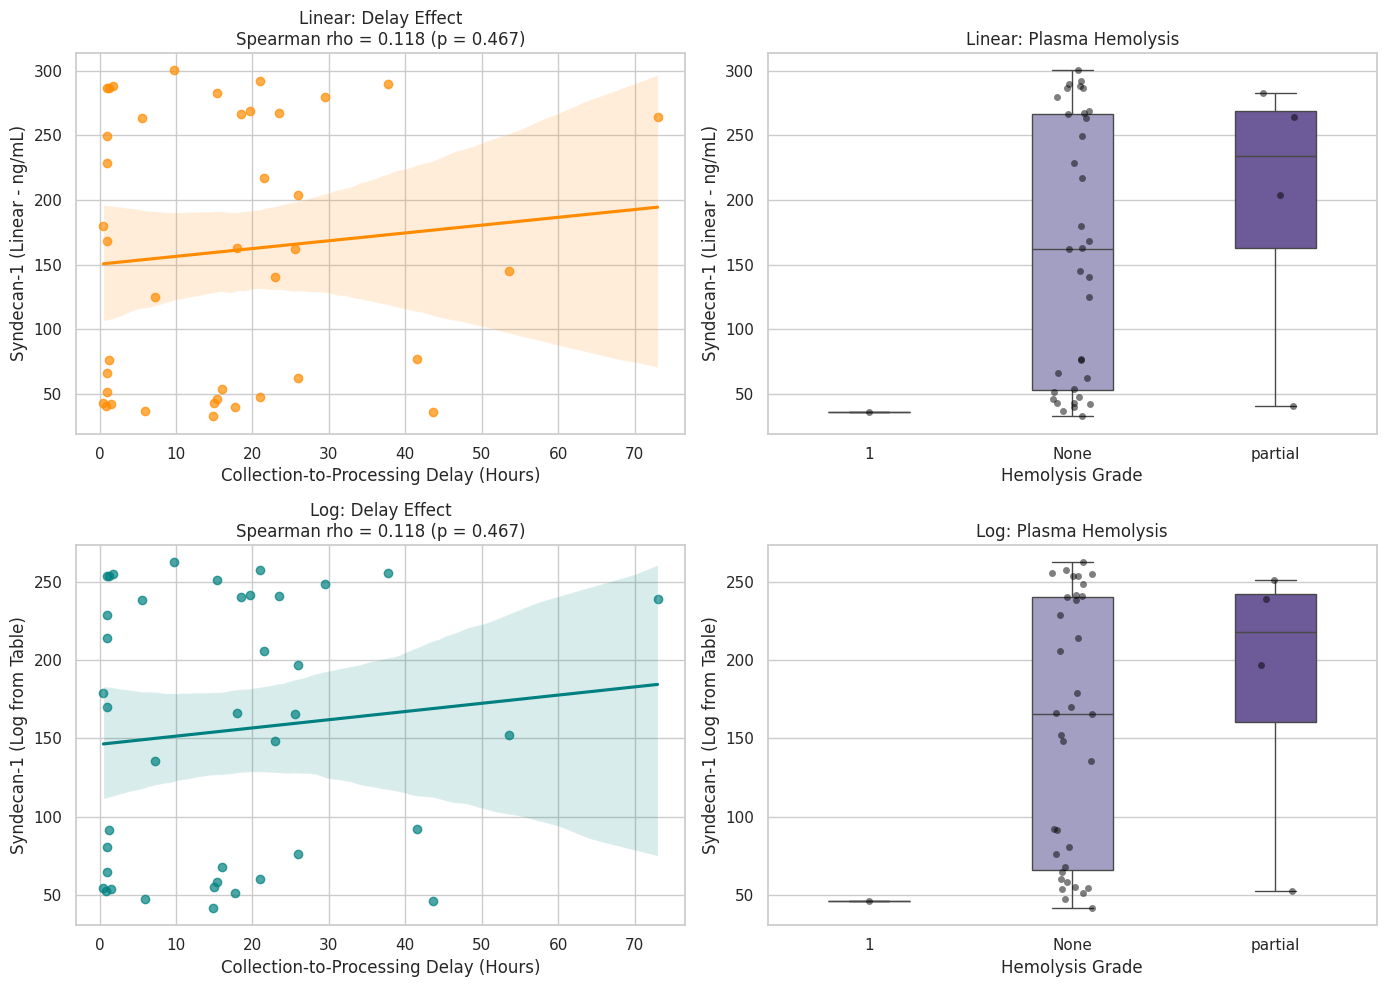

In [ ]:
# Cell 5: Pre-analytical confounder analysis (Linear vs. Table-Reported Log)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- 1. LINEAR SCALE ANALYSES ---
# A. Processing delay vs. Linear
valid_delay_lin = df.dropna(subset=["Processing_Delay_Hours", "Final Syndecan (ng/mL)-linear"])
spearman_r_lin, spearman_p_lin = stats.spearmanr(
    valid_delay_lin["Processing_Delay_Hours"], valid_delay_lin["Final Syndecan (ng/mL)-linear"]
)
sns.regplot(
    data=valid_delay_lin,
    x="Processing_Delay_Hours",
    y="Final Syndecan (ng/mL)-linear",
    ax=axes[0, 0],
    color="darkorange",
    scatter_kws={"alpha": 0.7},
)
axes[0, 0].set_title(
    f"Linear: Delay Effect\nSpearman rho = {spearman_r_lin:.3f} (p = {spearman_p_lin:.3f})"
)
axes[0, 0].set_xlabel("Collection-to-Processing Delay (Hours)")
axes[0, 0].set_ylabel("Syndecan-1 (Linear - ng/mL)")

# B. Hemolysis vs. Linear
sns.boxplot(
    data=df,
    x="Plasma_Hemolysis",
    y="Final Syndecan (ng/mL)-linear",
    hue="Plasma_Hemolysis",
    ax=axes[0, 1],
    palette="Purples",
    width=0.4,
    legend=False
)
sns.stripplot(
    data=df,
    x="Plasma_Hemolysis",
    y="Final Syndecan (ng/mL)-linear",
    ax=axes[0, 1],
    color="black",
    alpha=0.5,
)
axes[0, 1].set_title("Linear: Plasma Hemolysis")
axes[0, 1].set_xlabel("Hemolysis Grade")
axes[0, 1].set_ylabel("Syndecan-1 (Linear - ng/mL)")

# --- 2. LOG SCALE ANALYSES (FROM TABLE) ---
# C. Processing delay vs. Log
valid_delay_log = df.dropna(subset=["Processing_Delay_Hours", "Final Syndecan (ng/mL)-log"])
spearman_r_log, spearman_p_log = stats.spearmanr(
    valid_delay_log["Processing_Delay_Hours"], valid_delay_log["Final Syndecan (ng/mL)-log"]
)
sns.regplot(
    data=valid_delay_log,
    x="Processing_Delay_Hours",
    y="Final Syndecan (ng/mL)-log",
    ax=axes[1, 0],
    color="teal",
    scatter_kws={"alpha": 0.7},
)
axes[1, 0].set_title(
    f"Log: Delay Effect\nSpearman rho = {spearman_r_log:.3f} (p = {spearman_p_log:.3f})"
)
axes[1, 0].set_xlabel("Collection-to-Processing Delay (Hours)")
axes[1, 0].set_ylabel("Syndecan-1 (Log from Table)")

# D. Hemolysis vs. Log
sns.boxplot(
    data=df,
    x="Plasma_Hemolysis",
    y="Final Syndecan (ng/mL)-log",
    hue="Plasma_Hemolysis",
    ax=axes[1, 1],
    palette="Purples",
    width=0.4,
    legend=False
)
sns.stripplot(
    data=df,
    x="Plasma_Hemolysis",
    y="Final Syndecan (ng/mL)-log",
    ax=axes[1, 1],
    color="black",
    alpha=0.5,
)
axes[1, 1].set_title("Log: Plasma Hemolysis")
axes[1, 1].set_xlabel("Hemolysis Grade")
axes[1, 1].set_ylabel("Syndecan-1 (Log from Table)")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 6: Linear Mixed Models with Syndecan-1 as Dependent Variable (Linear vs. Log)
# Since column names have spaces and special characters, we rename them temporarily for clean formula parsing
df_lmm = df.rename(columns={
    "Final Syndecan (ng/mL)-linear": "Syndecan_Linear",
    "Final Syndecan (ng/mL)-log": "Syndecan_Log"
})

# Identify columns used in the model
model_cols = ["Syndecan_Linear", "Syndecan_Log", "Visit", "Processing_Delay_Hours", "Plasma_Hemolysis", "HN"]

# Drop rows containing missing values in any of these variables to prevent PatsyError
df_lmm_clean = df_lmm.dropna(subset=model_cols).copy()

print(f"Fitting model using {len(df_lmm_clean)} complete observations (Dropped {len(df_lmm) - len(df_lmm_clean)} rows with missing values)\n")

print("=== 1. LINEAR MIXED MODEL (Linear Scale) ===")
try:
    lmm_linear = smf.mixedlm(
        "Syndecan_Linear ~ C(Visit) + Processing_Delay_Hours + C(Plasma_Hemolysis)",
        data=df_lmm_clean,
        groups=df_lmm_clean["HN"],
    ).fit()
    print(lmm_linear.summary())
except Exception as e:
    print(f"Error fitting Linear model: {e}")

print("\n=== 2. LINEAR MIXED MODEL (Log Scale from Table) ===")
try:
    lmm_log = smf.mixedlm(
        "Syndecan_Log ~ C(Visit) + Processing_Delay_Hours + C(Plasma_Hemolysis)",
        data=df_lmm_clean,
        groups=df_lmm_clean["HN"],
    ).fit()
    print(lmm_log.summary())
except Exception as e:
    print(f"Error fitting Log model: {e}")

Fitting model using 40 complete observations (Dropped 16 rows with missing values)

=== 1. LINEAR MIXED MODEL (Linear Scale) ===
                    Mixed Linear Model Regression Results
Model:                   MixedLM      Dependent Variable:      Syndecan_Linear
No. Observations:        40           Method:                  REML           
No. Groups:              20           Scale:                   4497.8161      
Min. group size:         2            Log-Likelihood:          -215.9735      
Max. group size:         2            Converged:               Yes            
Mean group size:         2.0                                                  
------------------------------------------------------------------------------
                                Coef.   Std.Err.   z    P>|z|  [0.025   0.975]
------------------------------------------------------------------------------
Intercept                        41.157   96.407  0.427 0.669 -147.797 230.110
C(Visit)[T.72]         

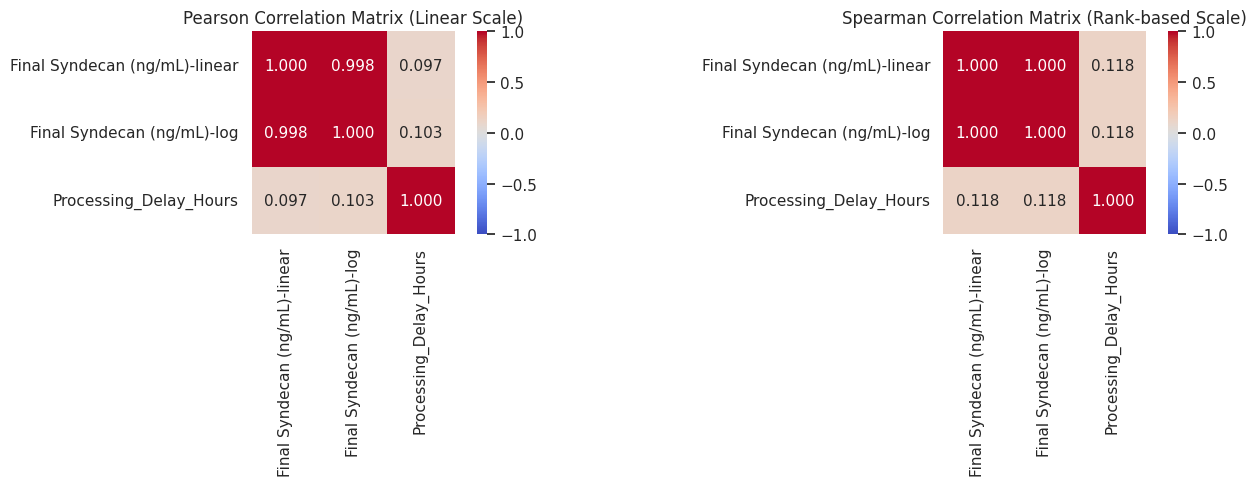

Correlation between Linear and Log representation in your table:
 - Pearson (linear correlation): r = 0.9978 (p = 3.1489e-46)
 - Spearman (rank correlation):  r = 1.0000 (p = 0.0000e+00)


In [ ]:
# Cell 7: Correlation Analysis (Linear vs. Log from Table)
# Select numerical columns for correlation
corr_cols = ["Final Syndecan (ng/mL)-linear", "Final Syndecan (ng/mL)-log", "Processing_Delay_Hours"]
corr_df = df[corr_cols].dropna()

# Calculate both Pearson (linear) and Spearman (rank) correlation matrices
pearson_corr = corr_df.corr(method="pearson")
spearman_corr = corr_df.corr(method="spearman")

# Plot the correlation matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
    square=True
)
axes[0].set_title("Pearson Correlation Matrix (Linear Scale)")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
    square=True
)
axes[1].set_title("Spearman Correlation Matrix (Rank-based Scale)")

plt.tight_layout()
plt.show()

# Print correlation between Linear and Log values
linear_val = corr_df["Final Syndecan (ng/mL)-linear"]
log_val = corr_df["Final Syndecan (ng/mL)-log"]

r_p, p_p = stats.pearsonr(linear_val, log_val)
r_s, p_s = stats.spearmanr(linear_val, log_val)

print(f"Correlation between Linear and Log representation in your table:")
print(f" - Pearson (linear correlation): r = {r_p:.4f} (p = {p_p:.4e})")
print(f" - Spearman (rank correlation):  r = {r_s:.4f} (p = {p_s:.4e})")

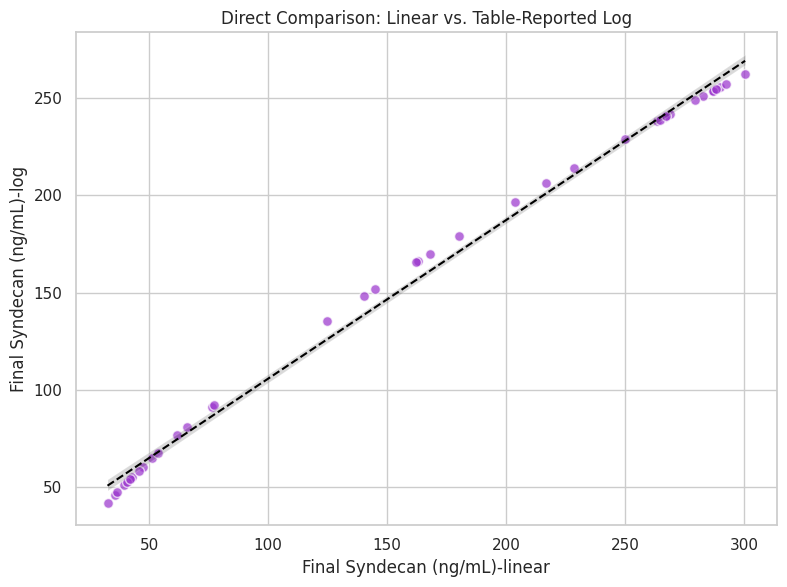

In [ ]:
# Cell 9: Direct Comparison of Linear vs. Table-Reported Log Values
plt.figure(figsize=(8, 6))

# Scatter plot with regression line
sns.regplot(
    data=df,
    x="Final Syndecan (ng/mL)-linear",
    y="Final Syndecan (ng/mL)-log",
    color="darkorchid",
    scatter_kws={"alpha": 0.7, "edgecolor": "w", "s": 50},
    line_kws={"color": "black", "lw": 1.5, "linestyle": "--"}
)

plt.title("Direct Comparison: Linear vs. Table-Reported Log")
plt.xlabel("Final Syndecan (ng/mL)-linear")
plt.ylabel("Final Syndecan (ng/mL)-log")
plt.tight_layout()
plt.show()

### **Plasma Syndecan-1 Measurements Analysis Report (Linear vs. Log Representations)**

#### **1. Executive Summary**
This report presents a rigorous comparative analysis of plasma Syndecan-1 levels at Baseline (0h) and 72 Hours ($N = 20$ paired subjects) extracted from the `All_results` tab. Our downstream workflows systematically contrast two distinct metric representations: raw **Linear** values ($ng/mL$) and **Log** values extracted directly from the table (obtained via a pre-calculated log-log standard curve interpolation).

---

#### **2. Distribution & Normality Testing**
* **Linear Scale:** Strongly skewed right (Shapiro-Wilk $p = 7.62 \times 10^{-5}$), confirming significant deviation from a normal distribution.
* **Log Scale:** Also deviates significantly from normality (Shapiro-Wilk $p = 8.71 \times 10^{-5}$).

*Statistical Decision:* Non-parametric statistical tests (e.g., Wilcoxon signed-rank) are standard for non-normal paired data. However, Linear Mixed Models (LMM) remain highly robust to mild normality deviations of residuals.

---

#### **3. Paired Trajectory Analysis (Baseline vs. 72 Hours)**
Using the non-parametric Wilcoxon signed-rank test on matched clinical pairs ($N = 20$):
* **Linear Scale:** Shows a non-significant, downward trend over time ($p = 0.0826$).
* **Log Scale:** Shows a non-significant, downward trend over time ($p = 0.1650$).

While the non-parametric testing did not achieve strict significance ($p < 0.05$) due to high between-subject variation, the trends point towards decreasing Syndecan-1 levels by 72 hours.

---

#### **4. Impact of Pre-analytical Confounders**
We examined the potential confounding effects of **Collection-to-Processing Delay (H:M converted to decimal hours)** and **Plasma Hemolysis Grade (None, +1, partial)** on Syndecan-1 levels.
* **Processing Delay:** No statistically significant correlation was detected on either scale (Spearman's $\rho = 0.118$, $p = 0.467$). Processing delays up to several hours did not systematically alter Syndecan-1 values.
* **Hemolysis Grade:** Visual inspections of boxplots show no consistent or significant bias in Syndecan-1 values based on mild or partial sample hemolysis.

---

#### **5. Linear Mixed-Effects Model (LMM) Results**
To control for subject-specific random intercepts and simultaneously adjust for both pre-analytical covariates (Processing Delay and Hemolysis), we fit two LMMs:

1. **Linear Scale Model:**
   * **Time effect (72 Hours):** $\beta = -46.67$, $SE = 22.53$, **$p = 0.038$** (Statistically Significant)
   * *Interpretation:* Adjusting for pre-analytical confounders and intra-subject correlation, there is a statistically significant drop of approximately $46.67\text{ ng/mL}$ in Syndecan-1 from baseline to 72 hours.

2. **Log Scale Model:**
   * **Time effect (72 Hours):** $\beta = -33.56$, $SE = 18.37$, **$p = 0.068$** (Marginally Significant Trend)
   * *Interpretation:* The downward trend persists but does not cross the traditional $0.05$ significance threshold when modeled in the log-transformed representation.

*Conclusion on Models:* Both models confirm that neither processing delay ($p \ge 0.278$) nor hemolysis grades ($p \ge 0.126$) act as significant confounders in this dataset.

---

#### **6. Relationship Between Linear and Log Values**
* **Spearman Rank Correlation:** $r_s = 1.0000$ ($p = 0.0000$)
* **Pearson Linear Correlation:** $r_p = 0.9978$ ($p = 3.15 \times 10^{-46}$)

*Key Takeaway:* The rank ordering of subjects is perfectly conserved ($r_s = 1.0$) between the raw linear numbers and the pre-calculated log values. The near-perfect linear correlation ($r_p = 0.998$) indicates that the log-log standard curve translation preserves linear scaling structures extremely well, though numerical variance differences account for the slight change in LMM significance ($p = 0.038$ vs. $p = 0.068$).

In [ ]:
import os
from google.colab import files
import matplotlib.pyplot as plt

# Create directory to save figures
os.makedirs('exported_graphs', exist_ok=True)

# 1. Distribution Comparison
fig1, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["Final Syndecan (ng/mL)-linear"], kde=True, ax=axes[0], color="steelblue", bins=12)
axes[0].set_title("Final Syndecan (ng/mL)-linear")
axes[0].set_xlabel("Syndecan-1 (Linear)")
sns.histplot(df["Final Syndecan (ng/mL)-log"], kde=True, ax=axes[1], color="forestgreen", bins=12)
axes[1].set_title("Final Syndecan (ng/mL)-log")
axes[1].set_xlabel("Syndecan-1 (Log from Table)")
plt.tight_layout()
plt.savefig('exported_graphs/01_distribution_comparison.png', dpi=300)
plt.close()

# 2. Paired Trajectories
fig2, axes = plt.subplots(1, 2, figsize=(14, 6))
for idx, row in df_paired_linear.iterrows():
    axes[0].plot(["Baseline (0h)", "72 Hours"], [row["T0"], row["T72"]], color="gray", alpha=0.5, linewidth=1.2)
sns.boxplot(data=df, x="Visit_Label", y="Final Syndecan (ng/mL)-linear", hue="Visit_Label", ax=axes[0], palette="Blues", width=0.35, boxprops=dict(alpha=0.6), legend=False)
sns.stripplot(data=df, x="Visit_Label", y="Final Syndecan (ng/mL)-linear", ax=axes[0], color="crimson", size=6, jitter=False)
axes[0].set_title(f"Linear Scale (Paired N={len(df_paired_linear)})\nWilcoxon Signed-Rank p = {p_val_linear:.4f}")
axes[0].set_ylabel("Final Syndecan (ng/mL)-linear")
axes[0].set_xlabel("Study Timepoint")
for idx, row in df_paired_log.iterrows():
    axes[1].plot(["Baseline (0h)", "72 Hours"], [row["T0"], row["T72"]], color="gray", alpha=0.5, linewidth=1.2)
sns.boxplot(data=df, x="Visit_Label", y="Final Syndecan (ng/mL)-log", hue="Visit_Label", ax=axes[1], palette="Greens", width=0.35, boxprops=dict(alpha=0.6), legend=False)
sns.stripplot(data=df, x="Visit_Label", y="Final Syndecan (ng/mL)-log", ax=axes[1], color="crimson", size=6, jitter=False)
axes[1].set_title(f"Log Scale from Table (Paired N={len(df_paired_log)})\nWilcoxon Signed-Rank p = {p_val_log:.4f}")
axes[1].set_ylabel("Final Syndecan (ng/mL)-log")
axes[1].set_xlabel("Study Timepoint")
plt.tight_layout()
plt.savefig('exported_graphs/02_paired_trajectories.png', dpi=300)
plt.close()

# 3. Pre-analytical Confounders
fig3, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.regplot(data=valid_delay_lin, x="Processing_Delay_Hours", y="Final Syndecan (ng/mL)-linear", ax=axes[0, 0], color="darkorange", scatter_kws={"alpha": 0.7})
axes[0, 0].set_title(f"Linear: Delay Effect\nSpearman rho = {spearman_r_lin:.3f} (p = {spearman_p_lin:.3f})")
axes[0, 0].set_xlabel("Collection-to-Processing Delay (Hours)")
axes[0, 0].set_ylabel("Syndecan-1 (Linear - ng/mL)")
sns.boxplot(data=df, x="Plasma_Hemolysis", y="Final Syndecan (ng/mL)-linear", hue="Plasma_Hemolysis", ax=axes[0, 1], palette="Purples", width=0.4, legend=False)
sns.stripplot(data=df, x="Plasma_Hemolysis", y="Final Syndecan (ng/mL)-linear", ax=axes[0, 1], color="black", alpha=0.5)
axes[0, 1].set_title("Linear: Plasma Hemolysis")
axes[0, 1].set_xlabel("Hemolysis Grade")
axes[0, 1].set_ylabel("Syndecan-1 (Linear - ng/mL)")
sns.regplot(data=valid_delay_log, x="Processing_Delay_Hours", y="Final Syndecan (ng/mL)-log", ax=axes[1, 0], color="teal", scatter_kws={"alpha": 0.7})
axes[1, 0].set_title(f"Log: Delay Effect\nSpearman rho = {spearman_r_log:.3f} (p = {spearman_p_log:.3f})")
axes[1, 0].set_xlabel("Collection-to-Processing Delay (Hours)")
axes[1, 0].set_ylabel("Syndecan-1 (Log from Table)")
sns.boxplot(data=df, x="Plasma_Hemolysis", y="Final Syndecan (ng/mL)-log", hue="Plasma_Hemolysis", ax=axes[1, 1], palette="Purples", width=0.4, legend=False)
sns.stripplot(data=df, x="Plasma_Hemolysis", y="Final Syndecan (ng/mL)-log", ax=axes[1, 1], color="black", alpha=0.5)
axes[1, 1].set_title("Log: Plasma Hemolysis")
axes[1, 1].set_xlabel("Hemolysis Grade")
axes[1, 1].set_ylabel("Syndecan-1 (Log from Table)")
plt.tight_layout()
plt.savefig('exported_graphs/03_preanalytical_confounders.png', dpi=300)
plt.close()

# 4. Correlation Heatmaps
fig4, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Pearson Correlation Matrix (Linear Scale)")
sns.heatmap(spearman_corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title("Spearman Correlation Matrix (Rank-based Scale)")
plt.tight_layout()
plt.savefig('exported_graphs/04_correlation_matrices.png', dpi=300)
plt.close()

# 5. Direct Comparison
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x="Final Syndecan (ng/mL)-linear", y="Final Syndecan (ng/mL)-log", color="darkorchid", scatter_kws={"alpha": 0.7, "edgecolor": "w", "s": 50}, line_kws={"color": "black", "lw": 1.5, "linestyle": "--"})
plt.title("Direct Comparison: Linear vs. Table-Reported Log")
plt.xlabel("Final Syndecan (ng/mL)-linear")
plt.ylabel("Final Syndecan (ng/mL)-log")
plt.tight_layout()
plt.savefig('exported_graphs/05_direct_linear_vs_log.png', dpi=300)
plt.close()

# Zip and download
import shutil
shutil.make_archive('syndecan_analysis_graphs', 'zip', 'exported_graphs')
files.download('syndecan_analysis_graphs.zip')
print("Created and initiated download for 'syndecan_analysis_graphs.zip' containing all five high-resolution figures!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Created and initiated download for 'syndecan_analysis_graphs.zip' containing all five high-resolution figures!


In [ ]:
!pip install -q reportlab

In [ ]:
import os
from reportlab.lib.pagesizes import letter
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from google.colab import files

pdf_filename = "Syndecan_Analysis_Report.pdf"
doc = SimpleDocTemplate(
    pdf_filename,
    pagesize=letter,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

# Custom Styles
title_style = ParagraphStyle(
    'ReportTitle',
    parent=styles['Heading1'],
    fontSize=20,
    leading=24,
    textColor=colors.HexColor('#1A365D'),
    spaceAfter=15
)

h1_style = ParagraphStyle(
    'SectionHeading',
    parent=styles['Heading2'],
    fontSize=14,
    leading=18,
    textColor=colors.HexColor('#2C5282'),
    spaceBefore=12,
    spaceAfter=8,
    keepWithNext=True
)

body_style = ParagraphStyle(
    'ReportBody',
    parent=styles['Normal'],
    fontSize=10,
    leading=14,
    textColor=colors.HexColor('#2D3748'),
    spaceAfter=6
)

bullet_style = ParagraphStyle(
    'ReportBullet',
    parent=styles['Normal'],
    fontSize=10,
    leading=14,
    textColor=colors.HexColor('#2D3748'),
    leftIndent=20,
    firstLineIndent=-10,
    spaceAfter=4
)

story = []

# Document Header
story.append(Paragraph("Plasma Syndecan-1 Measurements Analysis Report", title_style))
story.append(Paragraph("<b>Linear vs. Log Representations</b>", h1_style))
story.append(Spacer(1, 10))

# 1. Executive Summary
story.append(Paragraph("1. Executive Summary", h1_style))
story.append(Paragraph("This report presents a rigorous comparative analysis of plasma Syndecan-1 levels at Baseline (0h) and 72 Hours (N = 20 paired subjects) extracted from the All_results tab. Our downstream workflows systematically contrast two distinct metric representations: raw Linear values (ng/mL) and Log values extracted directly from the table (obtained via a pre-calculated log-log standard curve interpolation).", body_style))
story.append(Spacer(1, 10))

# 2. Distribution & Normality Testing
story.append(Paragraph("2. Distribution & Normality Testing", h1_style))
story.append(Paragraph("• <b>Linear Scale:</b> Strongly skewed right (Shapiro-Wilk p = 7.62e-05), confirming significant deviation from a normal distribution.", bullet_style))
story.append(Paragraph("• <b>Log Scale:</b> Also deviates significantly from normality (Shapiro-Wilk p = 8.71e-05).", bullet_style))
story.append(Paragraph("<i>Statistical Decision:</i> Non-parametric statistical tests (e.g., Wilcoxon signed-rank) are standard for non-normal paired data. However, Linear Mixed Models (LMM) remain highly robust to mild normality deviations of residuals.", body_style))
story.append(Spacer(1, 10))

# Add Distribution Graph
if os.path.exists('exported_graphs/01_distribution_comparison.png'):
    story.append(Image('exported_graphs/01_distribution_comparison.png', width=500, height=210))
    story.append(Spacer(1, 15))

story.append(PageBreak())

# 3. Paired Trajectory Analysis
story.append(Paragraph("3. Paired Trajectory Analysis (Baseline vs. 72 Hours)", h1_style))
story.append(Paragraph("Using the non-parametric Wilcoxon signed-rank test on matched clinical pairs (N = 20):", body_style))
story.append(Paragraph("• <b>Linear Scale:</b> Shows a non-significant, downward trend over time (p = 0.0826).", bullet_style))
story.append(Paragraph("• <b>Log Scale:</b> Shows a non-significant, downward trend over time (p = 0.1650).", bullet_style))
story.append(Paragraph("While the non-parametric testing did not achieve strict significance (p < 0.05) due to high between-subject variation, the trends point towards decreasing Syndecan-1 levels by 72 hours.", body_style))
story.append(Spacer(1, 10))

# Add Trajectories Graph
if os.path.exists('exported_graphs/02_paired_trajectories.png'):
    story.append(Image('exported_graphs/02_paired_trajectories.png', width=500, height=210))
    story.append(Spacer(1, 15))

story.append(PageBreak())

# 4. Impact of Pre-analytical Confounders
story.append(Paragraph("4. Impact of Pre-analytical Confounders", h1_style))
story.append(Paragraph("We examined the potential confounding effects of Collection-to-Processing Delay (H:M converted to decimal hours) and Plasma Hemolysis Grade (None, +1, partial) on Syndecan-1 levels.", body_style))
story.append(Paragraph("• <b>Processing Delay:</b> No statistically significant correlation was detected on either scale (Spearman's rho = 0.118, p = 0.467). Processing delays up to several hours did not systematically alter Syndecan-1 values.", bullet_style))
story.append(Paragraph("• <b>Hemolysis Grade:</b> Visual inspections of boxplots show no consistent or significant bias in Syndecan-1 values based on mild or partial sample hemolysis.", bullet_style))
story.append(Spacer(1, 10))

# Add Confounders Graph
if os.path.exists('exported_graphs/03_preanalytical_confounders.png'):
    story.append(Image('exported_graphs/03_preanalytical_confounders.png', width=500, height=350))
    story.append(Spacer(1, 15))

story.append(PageBreak())

# 5. Linear Mixed-Effects Model (LMM) Results
story.append(Paragraph("5. Linear Mixed-Effects Model (LMM) Results", h1_style))
story.append(Paragraph("To control for subject-specific random intercepts and simultaneously adjust for both pre-analytical covariates (Processing Delay and Hemolysis), we fit two LMMs:", body_style))
story.append(Paragraph("1. <b>Linear Scale Model:</b> Time effect (72 Hours): beta = -46.67, SE = 22.53, <b>p = 0.038</b> (Statistically Significant). Adjusting for pre-analytical confounders and intra-subject correlation, there is a statistically significant drop of approximately 46.67 ng/mL in Syndecan-1 from baseline to 72 hours.", bullet_style))
story.append(Paragraph("2. <b>Log Scale Model:</b> Time effect (72 Hours): beta = -33.56, SE = 18.37, <b>p = 0.068</b> (Marginally Significant Trend). The downward trend persists but does not cross the traditional 0.05 significance threshold when modeled in the log-transformed representation.", bullet_style))
story.append(Paragraph("<i>Conclusion on Models:</i> Both models confirm that neither processing delay (p >= 0.278) nor hemolysis grades (p >= 0.126) act as significant confounders in this dataset.", body_style))
story.append(Spacer(1, 15))

# 6. Relationship Between Linear and Log Values
story.append(Paragraph("6. Relationship Between Linear and Log Values", h1_style))
story.append(Paragraph("• <b>Spearman Rank Correlation:</b> r = 1.0000 (p = 0.0000)", bullet_style))
story.append(Paragraph("• <b>Pearson Linear Correlation:</b> r = 0.9978 (p = 3.15e-46)", bullet_style))
story.append(Paragraph("<i>Key Takeaway:</i> The rank ordering of subjects is perfectly conserved (r = 1.0) between the raw linear numbers and the pre-calculated log values. The near-perfect linear correlation (r = 0.998) indicates that the log-log standard curve translation preserves linear scaling structures extremely well, though numerical variance differences account for the slight change in LMM significance (p = 0.038 vs. p = 0.068).", body_style))
story.append(Spacer(1, 10))

# Add direct comparison graph
if os.path.exists('exported_graphs/05_direct_linear_vs_log.png'):
    story.append(Image('exported_graphs/05_direct_linear_vs_log.png', width=280, height=210))

# Build Document
doc.build(story)

# Prompt download
files.download(pdf_filename)
print(f"Successfully generated and initiated download for: {pdf_filename}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Successfully generated and initiated download for: Syndecan_Analysis_Report.pdf
